# Practical 8 - Decision Trees and its Max Depth

Switching gears this time — instead of hypothesis tests, we're building an actual machine learning model. I'm using the **Pima Indian Diabetes dataset** from Kaggle and building a Decision Tree classifier with scikit-learn to predict whether someone has diabetes based on a handful of health measurements.

Loading the libraries first. Along with the usual pandas/matplotlib, I need a few things from scikit-learn: the train/test split, the DecisionTreeClassifier itself, and the plotting function for visualizing the tree.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

Loading the dataset and taking a quick look at it.

In [2]:
df = pd.read_csv("diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
print("Rows and columns:", df.shape)
print("\nColumn info:")
df.info()

Rows and columns: (768, 9)

Column info:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


Quick check on how balanced the dataset is — how many people tested positive for diabetes vs negative.

Outcome
0    500
1    268
Name: count, dtype: int64


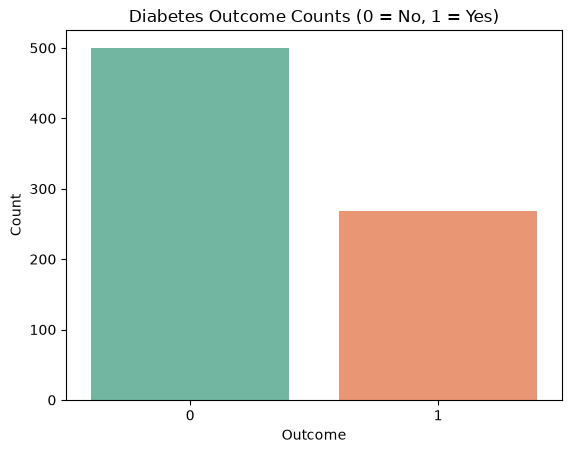

In [4]:
print(df["Outcome"].value_counts())
sns.countplot(data=df, x="Outcome", hue="Outcome", palette="Set2", legend=False)
plt.title("Diabetes Outcome Counts (0 = No, 1 = Yes)")
plt.xlabel("Outcome")
plt.ylabel("Count")
plt.show()

### Feature Selection

Here I'm splitting the columns into the two types the question asks for:
- **Target variable (dependent):** `Outcome` — this is what we're trying to predict (1 = has diabetes, 0 = doesn't)
- **Feature variables (independent):** everything else — Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, DiabetesPedigreeFunction, and Age. These are the inputs the model uses to make its prediction.

In [5]:
X = df.drop(columns=["Outcome"])   # feature variables
y = df["Outcome"]                   # target variable

print("Feature columns:", list(X.columns))
print("Target column: Outcome")

Feature columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
Target column: Outcome


### Splitting the data

Splitting into a training set (to build the tree) and a test set (to check how well it actually performs on data it hasn't seen). Using an 80/20 split here.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training set size:", X_train.shape[0])
print("Test set size:", X_test.shape[0])

Training set size: 614
Test set size: 154


### Building the Decision Tree

Now building the actual classifier. I'm limiting `max_depth` to 3 — this keeps the tree small enough to actually read and interpret, and also helps avoid overfitting (a tree with no depth limit tends to memorize the training data instead of learning general patterns).

In [7]:
clf = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=42)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("Test accuracy:", round(accuracy, 4))

Test accuracy: 0.7662


Let's also look at the confusion matrix and a classification report, just to get a fuller picture of how the model is doing beyond a single accuracy number.

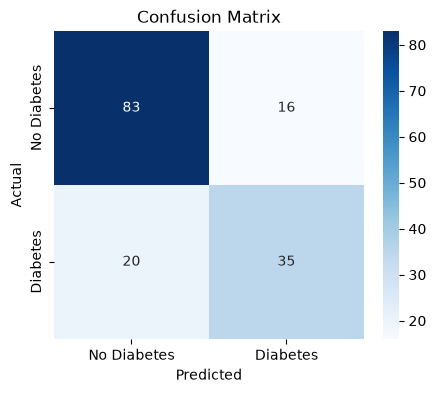

              precision    recall  f1-score   support

           0       0.81      0.84      0.82        99
           1       0.69      0.64      0.66        55

    accuracy                           0.77       154
   macro avg       0.75      0.74      0.74       154
weighted avg       0.76      0.77      0.76       154



In [8]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["No Diabetes","Diabetes"], yticklabels=["No Diabetes","Diabetes"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

print(classification_report(y_test, y_pred))

**About max depth:** `max_depth` controls how many levels of questions the tree is allowed to ask before making a decision. A shallow tree (like depth 3 here) is easier to interpret and less likely to overfit, but might miss some patterns. A very deep tree can capture more detail in the training data, but often ends up overfitting — performing great on training data but worse on new, unseen data. Picking the right depth is usually a balance between accuracy and keeping the model simple enough to trust and explain.

### Visualizing the tree

Here's what the tree actually looks like — each box shows the condition it's splitting on, the entropy and sample count at that point, and what it predicts.

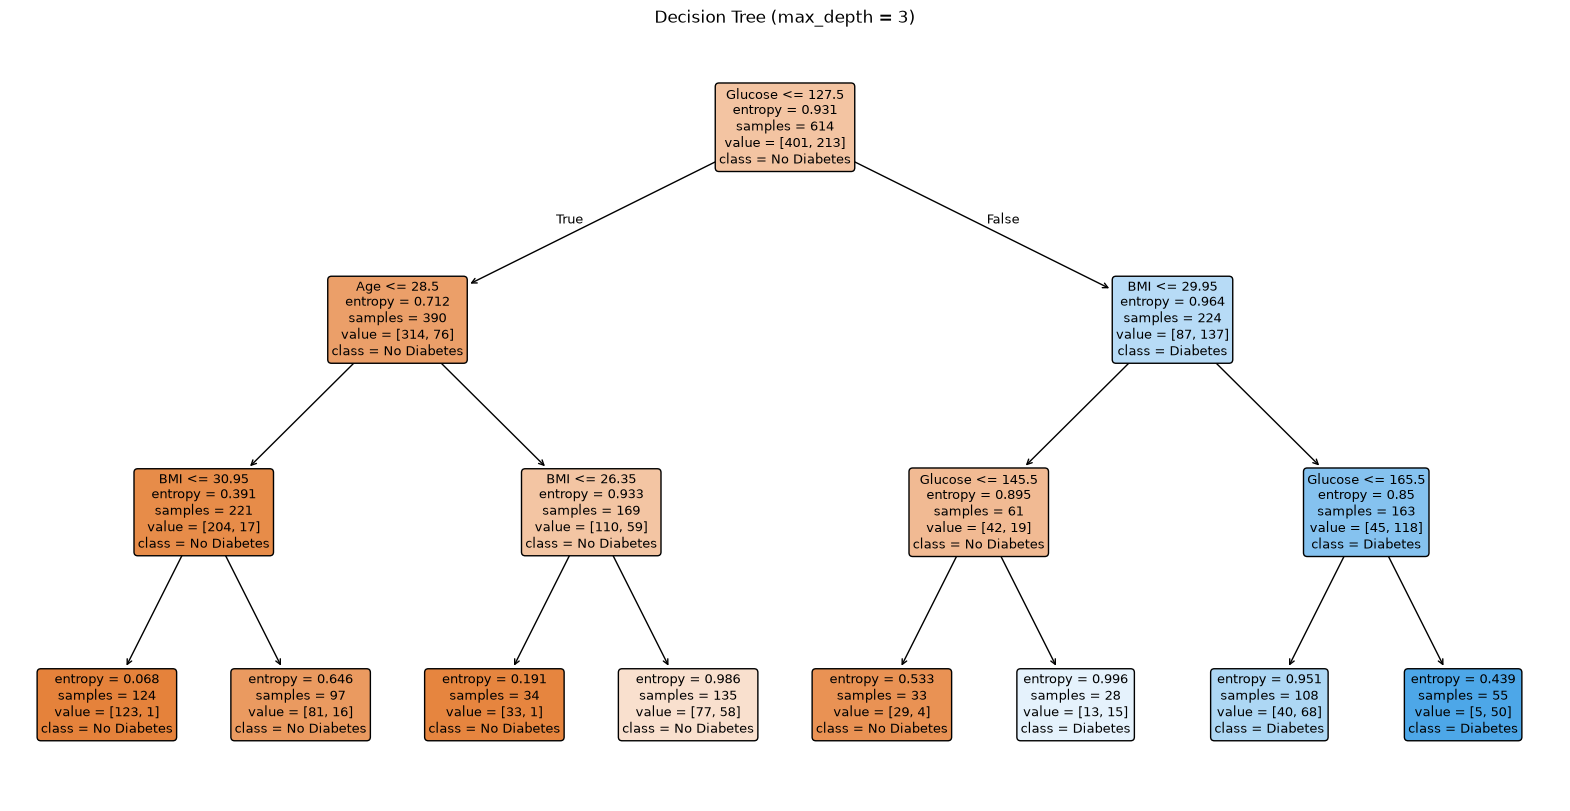

In [9]:
plt.figure(figsize=(20,10))
plot_tree(clf, feature_names=X.columns, class_names=["No Diabetes","Diabetes"], filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree (max_depth = 3)")
plt.show()

### Entropy, Information Gain, and Gini Index for the root node

The question asks us to justify *why* the tree picked the specific feature it did for the root (the very first split). Scikit-learn picks whichever feature and threshold gives the biggest reduction in impurity — so let's calculate that ourselves to see the reasoning behind it.

First, let's check what the tree actually picked as the root split.

In [10]:
root_feature = X.columns[clf.tree_.feature[0]]
root_threshold = clf.tree_.threshold[0]
print("Root node splits on:", root_feature)
print("Threshold:", round(root_threshold, 2))

Root node splits on: Glucose
Threshold: 127.5


Now let's manually calculate entropy and Gini index for the training data before the split (this is the "impurity" of just lumping everyone together), and then see how much that impurity drops after splitting on Glucose.

In [11]:
def entropy(labels):
    p = labels.value_counts(normalize=True)
    return -(p * np.log2(p)).sum()

def gini(labels):
    p = labels.value_counts(normalize=True)
    return 1 - (p ** 2).sum()

root_entropy = entropy(y_train)
root_gini = gini(y_train)

print("Entropy before splitting (root node):", round(root_entropy, 4))
print("Gini index before splitting (root node):", round(root_gini, 4))

Entropy before splitting (root node): 0.9313
Gini index before splitting (root node): 0.4531


In [12]:
left_mask = X_train[root_feature] <= root_threshold
right_mask = ~left_mask

y_left = y_train[left_mask]
y_right = y_train[right_mask]

n = len(y_train)
weighted_entropy = (len(y_left)/n) * entropy(y_left) + (len(y_right)/n) * entropy(y_right)
information_gain = root_entropy - weighted_entropy

weighted_gini = (len(y_left)/n) * gini(y_left) + (len(y_right)/n) * gini(y_right)
gini_gain = root_gini - weighted_gini

print(f"Split: {root_feature} <= {root_threshold:.2f}")
print("Left branch size:", len(y_left), " Right branch size:", len(y_right))
print("\nWeighted entropy after split:", round(weighted_entropy, 4))
print("Information gain:", round(information_gain, 4))
print("\nWeighted gini after split:", round(weighted_gini, 4))
print("Gini gain:", round(gini_gain, 4))

Split: Glucose <= 127.50
Left branch size: 390  Right branch size: 224

Weighted entropy after split: 0.8036
Information gain: 0.1277

Weighted gini after split: 0.3726
Gini gain: 0.0805


**Answer:** The tree picked **Glucose** (split around 127.5) as the root node. Before splitting, the entropy of the training data is about 0.93 and the Gini index is about 0.45 — both fairly high, meaning the two outcome classes (diabetes / no diabetes) are pretty mixed together at this point. After splitting on Glucose, the weighted entropy drops to about 0.80, giving an information gain of roughly 0.128 — the biggest drop in impurity of any feature, which is exactly why the algorithm picked it as the very first question to ask. The Gini index tells the same story: it drops from 0.45 to about 0.37, a gini gain of about 0.08. In plain terms, glucose level does the best job out of all the features at separating people who have diabetes from those who don't, so it makes sense that it ends up at the top of the tree.

### Which features mattered most overall

Beyond just the root node, let's see how much each feature contributed to the tree's decisions overall.

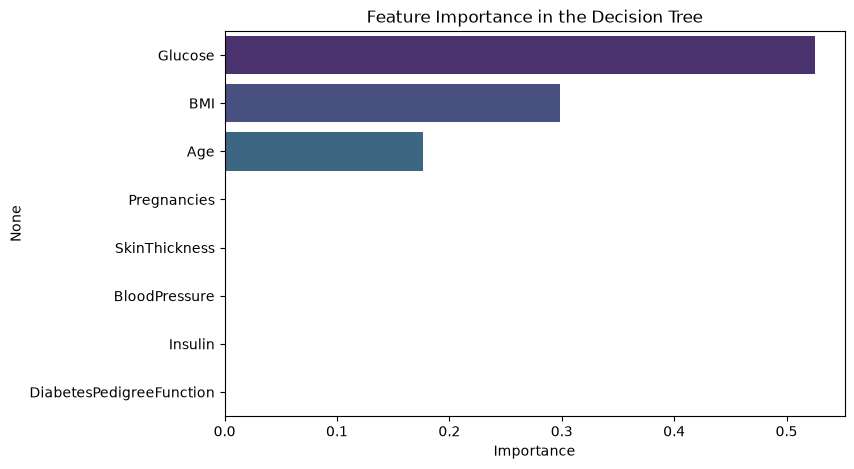

Glucose                     0.525396
BMI                         0.298151
Age                         0.176453
Pregnancies                 0.000000
SkinThickness               0.000000
BloodPressure               0.000000
Insulin                     0.000000
DiabetesPedigreeFunction    0.000000
dtype: float64


In [13]:
importances = pd.Series(clf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8,5))
sns.barplot(x=importances.values, y=importances.index, hue=importances.index, palette="viridis", legend=False)
plt.xlabel("Importance")
plt.title("Feature Importance in the Decision Tree")
plt.show()

print(importances)

Glucose comes out on top by a wide margin, which lines up with it being chosen as the root node — it's doing most of the heavy lifting in this tree, with BMI and Age picking up a decent share of the rest.

## Conclusion

Building this decision tree showed Glucose level as by far the most useful feature for predicting diabetes — it had the highest information gain and lowest resulting impurity when used as the root split, and it also came out on top in the feature importance ranking. Keeping `max_depth` at 3 kept the tree small enough to actually read and explain, at a reasonable trade-off with accuracy (around 77% on the test set). A deeper tree could likely push accuracy a bit higher, but would also get harder to interpret and more prone to overfitting the training data.